Лабораторная работа 1
Сбор, визуализация и анализ данных по графу научных публикаций по тематике music за период с 2021 года. Работа выполняется шагами: загрузка данных, предобработка, анализ текста, построение графа ключевых слов, кластеризация, анализ центральности и поиск похожих публикаций.

Ячейка 1. Импорт библиотек и инициализация. Подключаются pandas, numpy, scipy.sparse, networkx, matplotlib, seaborn, sklearn и requests для работы с Arxiv API. Для выгрузки словарей nltk через настроенный прокси включается разрешение proxied fetch. Скачиваются стоп слова, корпус wordnet и токенизатор punkt.

In [1]:
import time
import warnings
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import nltk
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings('ignore')

try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except AttributeError:
    pass

for corpus in ['stopwords', 'wordnet', 'punkt', 'punkt_tab', 'omw-1.4']:
    nltk.download(corpus, quiet=True)

plt.rcParams['figure.figsize'] = (12, 4)
sns.set_style('whitegrid')

Ячейка 2. Сбор данных через Arxiv API. Запрос all:music с фильтром по дате с 2021 года. Если файл arxiv_music_data.csv уже существует, он загружается, иначе данные скачиваются через requests, разбираются из XML и сохраняются в utf 8. Набор ограничен 1000 публикациями.

In [2]:
ARXIV_CSV = Path('arxiv_music_data.csv')
ARXIV_URL = (
    'https://export.arxiv.org/api/query'
    '?search_query=all:music+AND+submittedDate:[202101010000+TO+202612312359]'
    '&start=0'
    '&max_results=1000'
)
REQUEST_HEADERS = {'User-Agent': 'ITMO DataAnalysisLab (mailto:student@itmo.ru)'}
NAMESPACES = {'atom': 'http://www.w3.org/2005/Atom'}


def fetch_arxiv_feed(url: str) -> ET.Element:
    for attempt in range(3):
        try:
            response = requests.get(url, headers=REQUEST_HEADERS, timeout=120)
            response.raise_for_status()
            return ET.fromstring(response.content)
        except Exception as exc:
            if attempt == 2:
                raise RuntimeError('Ошибка загрузки данных с Arxiv API') from exc
            time.sleep(3)

results_limit = 1000

def load_arxiv_data(url: str, out_path: Path, limit: int = results_limit) -> pd.DataFrame:
    if out_path.exists():
        cached = pd.read_csv(out_path, encoding='utf-8')
        if len(cached) == limit:
            return cached
        print(f'Кеш содержит {len(cached)} строк, скачиваем набор на {limit}')
    root = fetch_arxiv_feed(url)
    papers = []
    for entry in root.findall('atom:entry', NAMESPACES):
        title = entry.find('atom:title', NAMESPACES).text.strip().replace('\n', ' ')
        summary = entry.find('atom:summary', NAMESPACES).text.strip().replace('\n', ' ')
        published = entry.find('atom:published', NAMESPACES).text
        year = int(published[:4])
        if year >= 2021:
            author_names = [a.find('atom:name', NAMESPACES).text for a in entry.findall('atom:author', NAMESPACES)]
            papers.append({'title': title, 'summary': summary, 'authors': '; '.join(author_names), 'year': year})
    result = pd.DataFrame(papers).head(limit)
    result.to_csv(out_path, index=False, encoding='utf-8')
    return result


df = load_arxiv_data(ARXIV_URL, ARXIV_CSV)
print(f'Загружено публикаций: {len(df)}')
print(f'Файл данных: {ARXIV_CSV.resolve()}')
df[['title', 'year']].head(3)

Загружено публикаций: 1000
Файл данных: D:\ITMO\7_SEM\Data Analysis and Information Retrieval\lab1\arxiv_music_data.csv


,title,year
0,Dorabella Cipher as Musical Inspiration,2025
1,Improving Choral Music Separation through Expr...,2022
2,musif: a Python package for symbolic music fea...,2023


Ячейка 3. Предобработка текста. Текст приводится к нижнему регистру и очищается от спецсимволов, затем токенизируется, освобождается от стоп слов и лемматизируется. Заголовок и аннотация каждой статьи объединяются в текстовое поле.

In [3]:
STOP_WORDS = set(stopwords.words('english'))
LEMMATIZER = WordNetLemmatizer()


def clean_text(text: str) -> str:
    reduced = ''.join(ch for ch in text.lower() if ch.isalpha() or ch.isspace())
    tokens = nltk.word_tokenize(reduced)
    tokens = [LEMMATIZER.lemmatize(word) for word in tokens if word not in STOP_WORDS and len(word) > 2]
    return ' '.join(tokens)


df['clean_text'] = (df['title'] + ' ' + df['summary']).apply(clean_text)
df[['title', 'clean_text']].head(2)

,title,clean_text
0,Dorabella Cipher as Musical Inspiration,dorabella cipher musical inspiration dorabella...
1,Improving Choral Music Separation through Expr...,improving choral music separation expressive s...


Ячейка 4. Разведочный анализ данных. Строятся два графика: распределение статей по годам и гистограмма длины текстов. Далее проверяется закон Ципфа на лог лог графике с теоретической кривой вида c / x.

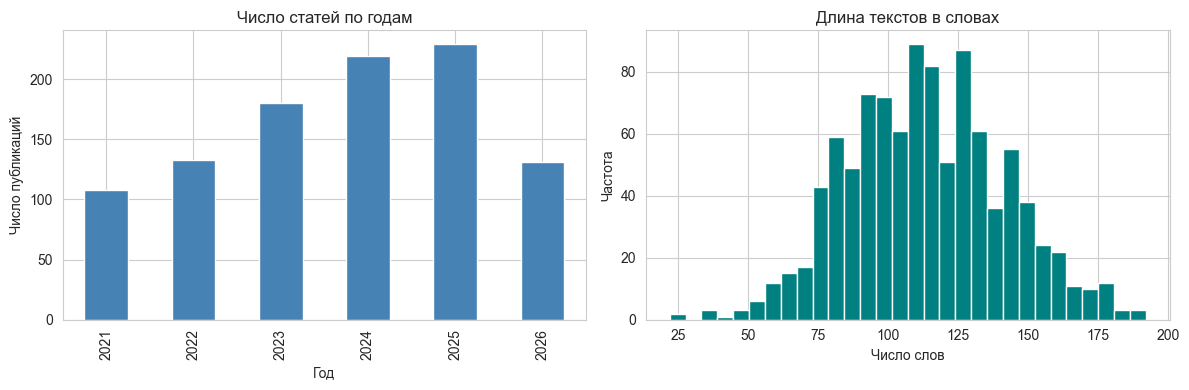

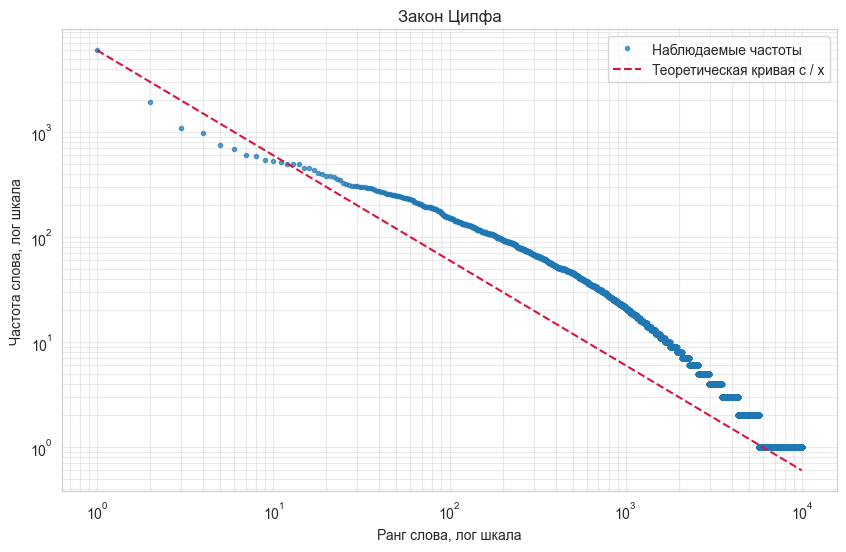

In [4]:
fig, axes = plt.subplots(1, 2)
ax_year = axes[0]
df['year'].value_counts().sort_index().plot(kind='bar', ax=ax_year, color='steelblue')
ax_year.set_title('Число статей по годам')
ax_year.set_xlabel('Год')
ax_year.set_ylabel('Число публикаций')

ax_length = axes[1]
text_lengths = df['clean_text'].str.split().str.len()
ax_length.hist(text_lengths, bins=30, color='teal', edgecolor='white')
ax_length.set_title('Длина текстов в словах')
ax_length.set_xlabel('Число слов')
ax_length.set_ylabel('Частота')
plt.tight_layout()
plt.show()

word_corpus = ' '.join(df['clean_text']).split()
frequencies = pd.Series(Counter(word_corpus)).sort_values(ascending=False)
ranks = np.arange(1, len(frequencies) + 1)
constant = frequencies.iloc[0]

plt.figure(figsize=(10, 6))
plt.loglog(ranks, frequencies.to_numpy(), marker='.', linestyle='none', alpha=0.7, label='Наблюдаемые частоты')
plt.loglog(ranks, constant / ranks, linestyle='dashed', color='crimson', label='Теоретическая кривая c / x')
plt.title('Закон Ципфа')
plt.xlabel('Ранг слова, лог шкала')
plt.ylabel('Частота слова, лог шкала')
plt.grid(True, which='both', alpha=0.4)
plt.legend()
plt.show()

Ячейка 5. Выделение ключевых слов. Используется TfidfVectorizer с диапазоном ngram от 1 до 3 и ограничением на 800 признаков. Термины с низким максимальным значением tf idf отбрасываются, чтобы оставить только значимые слова.

In [5]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=800,
    sublinear_tf=True,
    stop_words='english',
)
X = vectorizer.fit_transform(df['clean_text'])
all_terms = vectorizer.get_feature_names_out()
peak_tfidf = X.max(axis=0).toarray().ravel()
kept_terms = peak_tfidf >= 0.05
X = X[:, kept_terms]
keywords = all_terms[kept_terms]
print(f'Ключевых слов отобрано: {sum(kept_terms)} из {len(all_terms)}')

Ключевых слов отобрано: 800 из 800


Ячейка 6. Построение графа ключевых слов. Матрица со встречаемости вычисляется разреженно через умножение бинарной матрицы на её транспонированную версию. Для прореживания графа оставляются связи с весом не менее 3, из них отбираются 50 самых значимых по наибольшему весу. Граф визуализируется с помощью spring layout.

Граф ключевых слов: 33 узлов, 50 ребер
Вес ребер после фильтрации: от 201 до 640


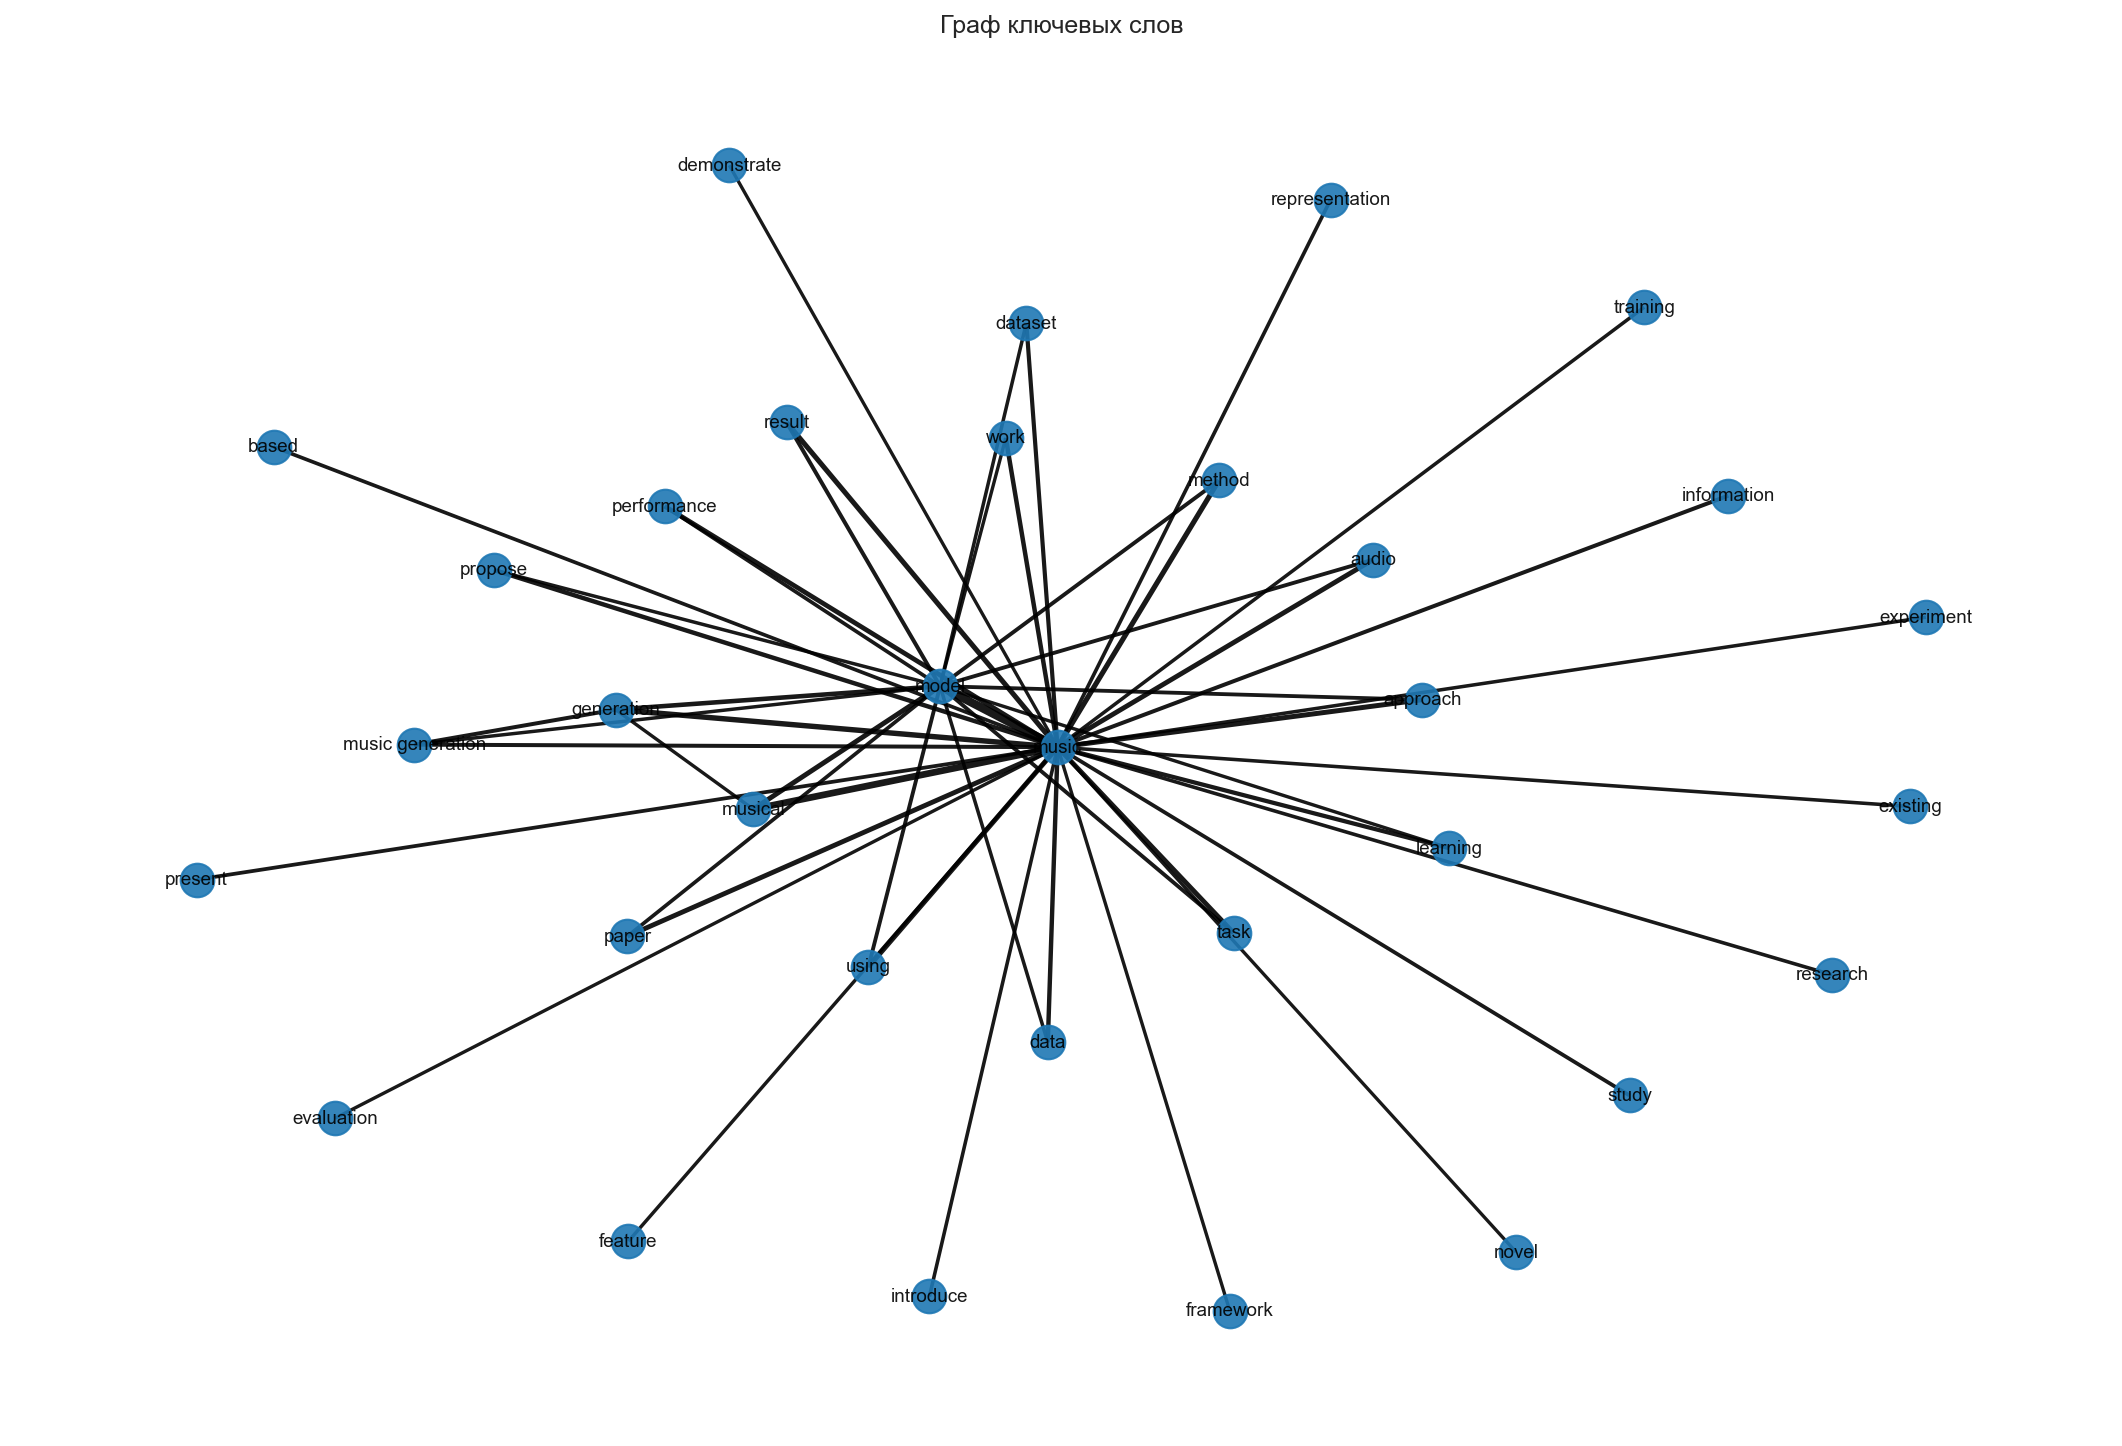

In [6]:
X_bin = (X > 0).astype(int)
cooccurrence = (X_bin.T @ X_bin).tocoo()

pair_weights: list[tuple[int, int, int]] = []
for i, j, weight in zip(cooccurrence.row, cooccurrence.col, cooccurrence.data):
    if i < j and weight >= 3:
        pair_weights.append((i, j, int(weight)))

top_edges = sorted(pair_weights, key=lambda item: item[2], reverse=True)[:50]

keyword_graph = nx.Graph()
for i, j, weight in top_edges:
    keyword_graph.add_edge(keywords[i], keywords[j], weight=weight)

print(f'Граф ключевых слов: {keyword_graph.number_of_nodes()} узлов, {keyword_graph.number_of_edges()} ребер')
lightest_edge = min(top_edges, key=lambda item: item[2])
heaviest_edge = top_edges[0]
print(f'Вес ребер после фильтрации: от {lightest_edge[2]} до {heaviest_edge[2]}')

pos = nx.spring_layout(keyword_graph, seed=42, weight='weight', k=0.8)
max_weight = max(keyword_graph[u][v]['weight'] for u, v in keyword_graph.edges())
edge_widths = [0.5 + 3.5 * keyword_graph[u][v]['weight'] / max_weight for u, v in keyword_graph.edges()]
plt.figure(figsize=(18, 12), dpi=150)
nx.draw_networkx(keyword_graph, pos, with_labels=True, node_size=260, font_size=9, alpha=0.9, width=edge_widths)
plt.title('Граф ключевых слов')
plt.axis('off')
plt.savefig('keyword_graph.png', dpi=200, bbox_inches='tight')
plt.show()

Ячейка 7. Кластеризация графа. Применяется жадная максимизация модулярности. Выводится значение модулярности и слова каждого кластера. Визуализация окрашена по кластерам, что показывает смысловые тематики внутри корпуса.

Модулярность: 0.0916
Кластер 0 из 22 слов: approach, based, demonstrate, evaluation, existing, experiment, feature, framework, information, introduce, method, music, novel, paper, performance, present, propose, representation, research, study, training, work
Кластер 1 из 11 слов: audio, data, dataset, generation, learning, model, music generation, musical, result, task, using


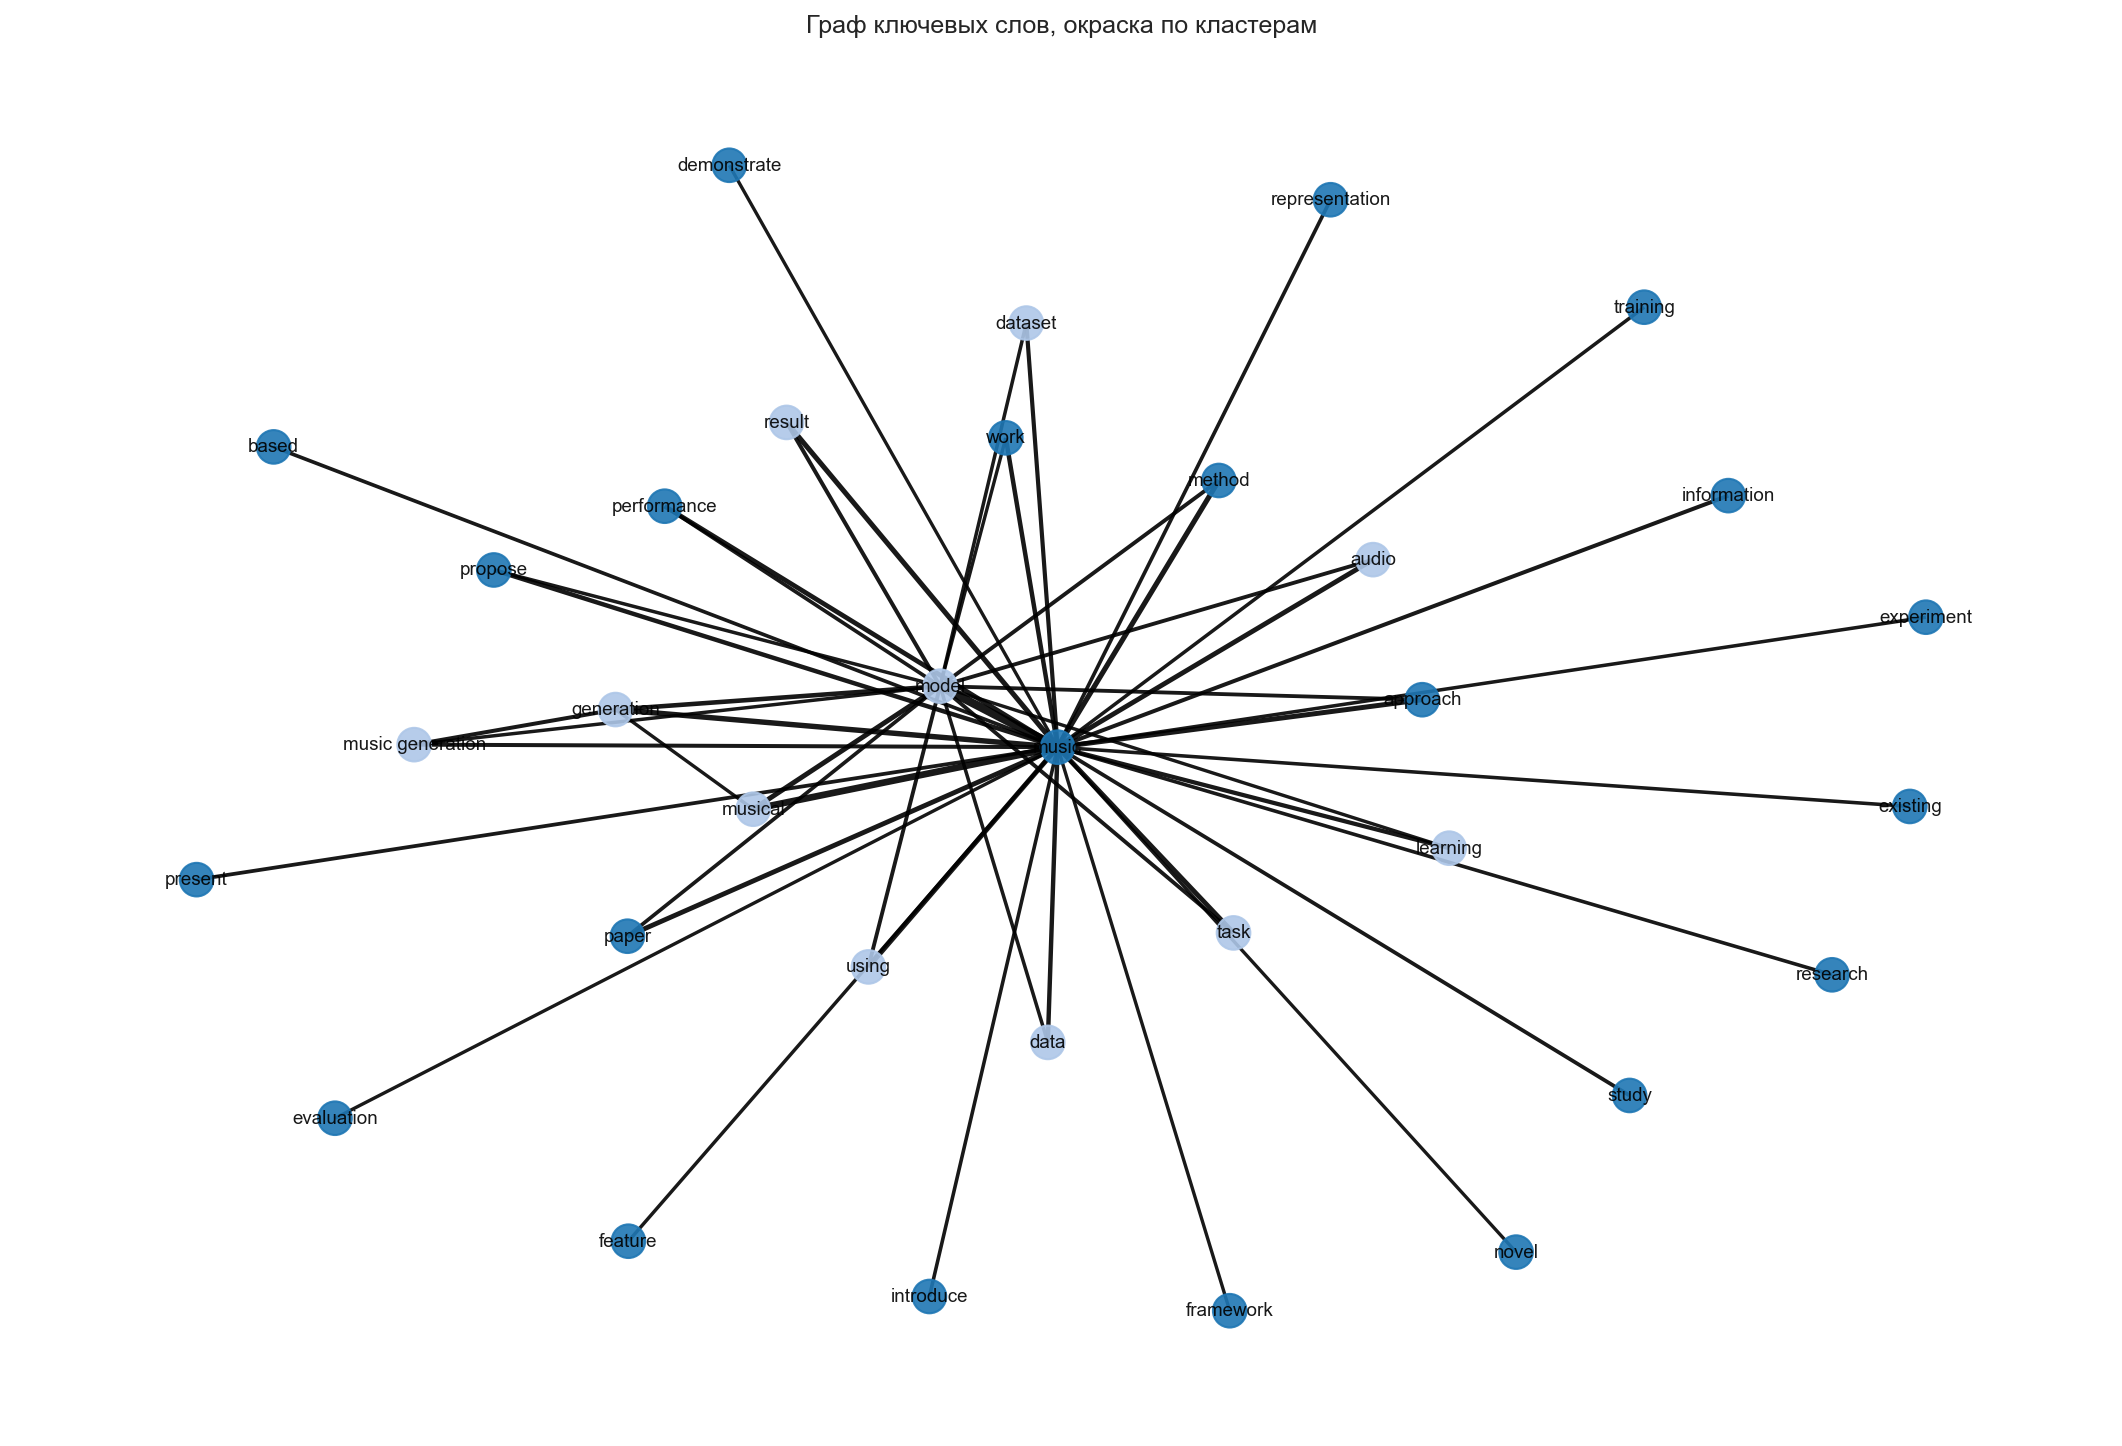

In [7]:
communities = list(nx.algorithms.community.greedy_modularity_communities(keyword_graph, weight='weight'))
modularity = nx.algorithms.community.modularity(keyword_graph, communities, weight='weight')
print(f'Модулярность: {modularity:.4f}')

node_cluster = {}
for cluster_index, community in enumerate(communities):
    words = sorted(community)
    node_cluster.update({word: cluster_index for word in words})
    print(f'Кластер {cluster_index} из {len(words)} слов: {", ".join(words)}')

pos = nx.spring_layout(keyword_graph, seed=42, weight='weight', k=0.8)
cmap = plt.get_cmap('tab20')
colors = [cmap(node_cluster[node] % 20) for node in keyword_graph.nodes()]
max_weight = max(keyword_graph[u][v]['weight'] for u, v in keyword_graph.edges())
edge_widths = [0.5 + 3.5 * keyword_graph[u][v]['weight'] / max_weight for u, v in keyword_graph.edges()]
plt.figure(figsize=(18, 12), dpi=150)
nx.draw_networkx(keyword_graph, pos, node_color=colors, with_labels=True, node_size=260, font_size=9, alpha=0.9, width=edge_widths)
plt.title('Граф ключевых слов, окраска по кластерам')
plt.axis('off')
plt.savefig('keyword_graph_clusters.png', dpi=200, bbox_inches='tight')
plt.show()

Ячейка 8. Анализ центральности. Для каждой метрики выводится топ 5 ключевых слов. Degree показывает общую связанность, betweenness выделяет слова мосты между тематиками, closeness отражает близость ко всем узлам, eigenvector подчеркивает соседей влиятельных слов.

In [8]:
degree_centrality = nx.degree_centrality(keyword_graph)
betweenness_centrality = nx.betweenness_centrality(keyword_graph, weight='weight')
closeness_centrality = nx.closeness_centrality(keyword_graph)

try:
    eigenvector_centrality = nx.eigenvector_centrality(keyword_graph, weight='weight', max_iter=1000)
except nx.PowerIterationFailedConvergence:
    eigenvector_centrality = nx.eigenvector_centrality_numpy(keyword_graph, weight='weight')


def top_words(centrality: dict[str, float], top_n: int = 10) -> list[tuple[str, float]]:
    return sorted(centrality.items(), key=lambda pair: pair[1], reverse=True)[:top_n]


for metric_name, values in {
    'Degree': degree_centrality,
    'Betweenness': betweenness_centrality,
    'Eigenvector': eigenvector_centrality,
    'Closeness': closeness_centrality,
}.items():
    print(f'Топ 5 по {metric_name}:')
    for word, score in top_words(values):
        print(f'  {word}: {score:.4f}')

Топ 5 по Degree:
  music: 1.0000
  model: 0.5312
  generation: 0.1250
  musical: 0.0938
  music generation: 0.0938
  method: 0.0625
  result: 0.0625
  approach: 0.0625
  using: 0.0625
  audio: 0.0625
Топ 5 по Betweenness:
  music: 0.7258
  model: 0.2359
  music generation: 0.0323
  generation: 0.0020
  musical: 0.0000
  method: 0.0000
  result: 0.0000
  approach: 0.0000
  using: 0.0000
  audio: 0.0000
Топ 5 по Eigenvector:
  music: 0.6058
  model: 0.4537
  musical: 0.2299
  generation: 0.2105
  method: 0.1536
  result: 0.1528
  using: 0.1483
  approach: 0.1473
  audio: 0.1458
  task: 0.1457
Топ 5 по Closeness:
  music: 1.0000
  model: 0.6809
  generation: 0.5333
  musical: 0.5246
  music generation: 0.5246
  method: 0.5161
  result: 0.5161
  approach: 0.5161
  using: 0.5161
  audio: 0.5161


Ячейка 9. Граф публикаций и поиск. Матрица смежности публикаций получена разреженным умножением, вес ребра равен числу общих ключевых слов. Результаты поиска сортируются по числу общих слов с запросом, при равной релевантности учитывается вес связи с лучшей статьей в графе, затем год публикации, в конце исходный порядок данных.

In [9]:
paper_adjacency = (X_bin @ X_bin.T).tocoo()

paper_graph = nx.Graph()
paper_graph.add_nodes_from(df.index.tolist())

for i, j, weight in zip(paper_adjacency.row, paper_adjacency.col, paper_adjacency.data):
    if i < j and weight >= 1:
        paper_graph.add_edge(int(i), int(j), weight=int(weight))

print(f'Граф публикаций: {paper_graph.number_of_nodes()} узлов, {paper_graph.number_of_edges()} ребер')


def search_similar_papers(query: str, data: pd.DataFrame, graph: nx.Graph, top_n: int = 3) -> pd.DataFrame:
    query_terms = set(clean_text(query).split())
    overlap = data['clean_text'].apply(lambda text: len(query_terms.intersection(text.split())))
    if overlap.max() == 0:
        overlap = data['title'].str.contains(query.split()[0], case=False, na=False).astype(int)

    ranked = pd.DataFrame(index=data.index)
    ranked['title'] = data['title']
    ranked['year'] = data['year']
    ranked['shared_terms'] = overlap.to_numpy()
    ranked['order'] = np.arange(len(data))

    best_paper = int(ranked.sort_values(
        by=['shared_terms', 'year', 'order'],
        ascending=[False, False, True],
        kind='stable',
    ).index[0])

    neighbors = graph[best_paper]
    ranked['graph_weight'] = np.array([
        neighbors[pub_id]['weight'] if pub_id in neighbors else 0
        for pub_id in data.index
    ])

    top_papers = ranked.sort_values(
        by=['shared_terms', 'graph_weight', 'year', 'order'],
        ascending=[False, False, False, True],
        kind='stable',
    ).head(top_n)

    print(f'Исходная публикация: {data.loc[best_paper, "title"]} ({data.loc[best_paper, "year"]})')
    for _, row in top_papers.iterrows():
        print(f'Совпадение: {int(row["shared_terms"])} общих слов, вес в графе {int(row["graph_weight"])}: {row["title"]} ({int(row["year"])})')
    return top_papers

Граф публикаций: 1000 узлов, 498444 ребер


Ячейка 10. Тестирование поиска. Выполняется вызов функции с запросом deep learning music generation и с заголовком существующей статьи из датасета. Выводится исходная статья и отсортированные похожие публикации с числом общих слов и весом в графе.

In [10]:
search_similar_papers('deep learning music generation', df, paper_graph)
search_similar_papers(df.iloc[0]['title'], df, paper_graph)

Исходная публикация: ProGress: Structured Music Generation via Graph Diffusion and Hierarchical Music Analysis (2025)
Совпадение: 4 общих слов, вес в графе 20: Generating music with sentiment using Transformer-GANs (2022)
Совпадение: 4 общих слов, вес в графе 19: Motifs, Phrases, and Beyond: The Modelling of Structure in Symbolic Music Generation (2024)
Совпадение: 4 общих слов, вес в графе 19: Graph-based Polyphonic Multitrack Music Generation (2023)
Исходная публикация: Dorabella Cipher as Musical Inspiration (2025)
Совпадение: 4 общих слов, вес в графе 0: Dorabella Cipher as Musical Inspiration (2025)
Совпадение: 2 общих слов, вес в графе 7: Exploring Musical Roots: Applying Audio Embeddings to Empower Influence Attribution for a Generative Music Model (2024)
Совпадение: 2 общих слов, вес в графе 6: SinTra: Learning an inspiration model from a single multi-track music segment (2022)


,title,year,shared_terms,order,graph_weight
0,Dorabella Cipher as Musical Inspiration,2025,4,0,0
676,Exploring Musical Roots: Applying Audio Embedd...,2024,2,676,7
716,SinTra: Learning an inspiration model from a s...,2022,2,716,6
